# GridWise EDA — BDG2 electricity subset

Quick EDA on the ETL output (`data/processed/electricity.parquet`, ~131 meters from the 200-building subset).
Plots are saved to `docs/plots/` and reused in the README.

In [1]:
import os, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
p = Path.cwd()
while not (p / 'gridwise').is_dir() and p != p.parent:
    p = p.parent
os.chdir(p)
print('cwd:', Path.cwd())
df = pd.read_parquet('data/processed/electricity.parquet')
print(df.shape, df.building_id.nunique(), 'meters')

cwd: /Users/prnv/Desktop/projects/GridWise
(2243906, 12) 131 meters


## 1. Average load profile by hour of day, per building type

saved


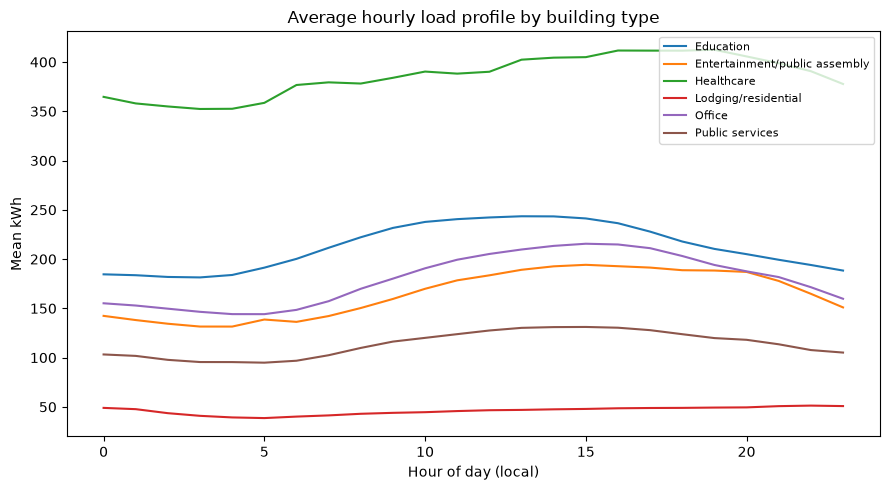

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
for use, g in df.groupby('primaryspaceusage'):
    if len(g) > 50_000:
        prof = g.groupby(g.timestamp.dt.hour).kwh.mean()
        ax.plot(prof.index, prof.values, label=use)
ax.set_xlabel('Hour of day (local)'); ax.set_ylabel('Mean kWh')
ax.legend(fontsize=8); ax.set_title('Average hourly load profile by building type')
fig.tight_layout(); Path('../docs/plots').mkdir(parents=True, exist_ok=True)
fig.savefig('docs/plots/load_profile_by_type.png', dpi=150)
print('saved')

## 2. Temperature vs load (the cooling/heating signature)

saved


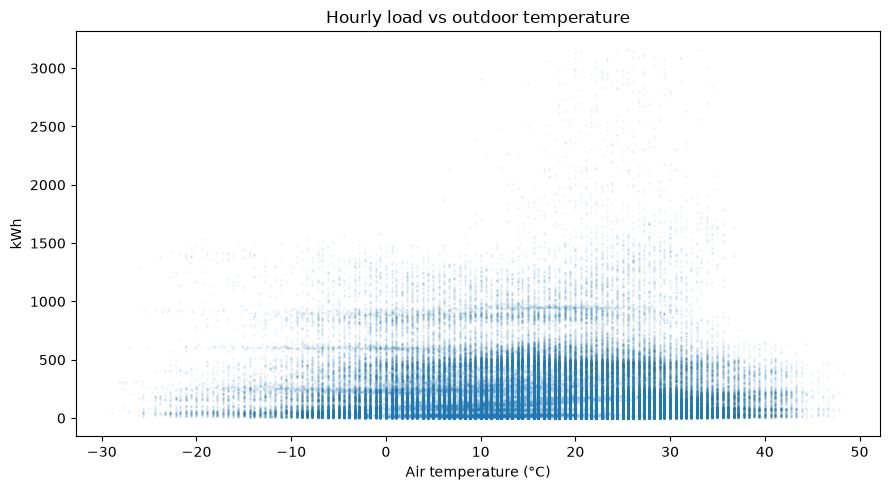

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
s = df.dropna(subset=['airTemperature']).sample(200_000, random_state=0)
ax.scatter(s.airTemperature, s.kwh, s=1, alpha=0.05)
ax.set_xlabel('Air temperature (°C)'); ax.set_ylabel('kWh')
ax.set_title('Hourly load vs outdoor temperature')
fig.tight_layout(); fig.savefig('docs/plots/load_vs_temperature.png', dpi=150)
print('saved')

## 3. Weekday vs weekend load

/var/folders/j5/h45xv0vd3sz7b8_wlb7c3j400000gn/T/ipykernel_12405/2868808915.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  wd = df[df.timestamp.dt.dayofweek < 5].groupby(df.timestamp.dt.hour).kwh.mean()
/var/folders/j5/h45xv0vd3sz7b8_wlb7c3j400000gn/T/ipykernel_12405/2868808915.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  we = df[df.timestamp.dt.dayofweek >= 5].groupby(df.timestamp.dt.hour).kwh.mean()


saved


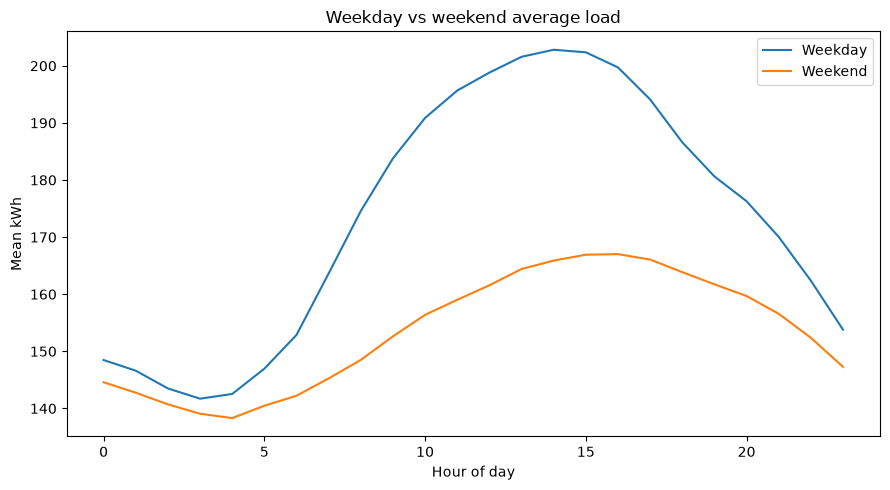

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
wd = df[df.timestamp.dt.dayofweek < 5].groupby(df.timestamp.dt.hour).kwh.mean()
we = df[df.timestamp.dt.dayofweek >= 5].groupby(df.timestamp.dt.hour).kwh.mean()
ax.plot(wd.index, wd.values, label='Weekday')
ax.plot(we.index, we.values, label='Weekend')
ax.set_xlabel('Hour of day'); ax.set_ylabel('Mean kWh')
ax.legend(); ax.set_title('Weekday vs weekend average load')
fig.tight_layout(); fig.savefig('docs/plots/weekday_vs_weekend.png', dpi=150)
print('saved')